# My first neural network

An MLP written from scratch (64 → 64 ReLU → 10 softmax) that classifies the scikit-learn **Digits** images. Only the gradient is automatic, with `autograd`. Design: `spec.md`, `architecture.md`, `tasks.md`.

Run with **Restart kernel and run all**.

## 0. Setup

`autograd.numpy` (`anp`) is used wherever the gradient flows; plain `numpy` (`np`) everywhere else. All settings live in `CONFIG`.

In [1]:
import autograd.numpy as anp
import numpy as np
import matplotlib.pyplot as plt
from autograd import value_and_grad
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

CONFIG = {"seed": 0, "test_size": 0.2, "layer_sizes": [64, 64, 10],
          "learning_rate": 0.1, "batch_size": 32, "epochs": 30}
print(CONFIG)

{'seed': 0, 'test_size': 0.2, 'layer_sizes': [64, 64, 10], 'learning_rate': 0.1, 'batch_size': 32, 'epochs': 30}


## 1. Data

Load the 1,797 images (64 pixels each), split 80/20 **stratified** with the seed, and standardize each pixel with the **training** mean and std only, so no test information leaks into training. Pixels that are always 0 have std 0; it is replaced by 1 to avoid dividing by zero. The raw test images are kept for display later.

In [2]:
def standardize(X_train, X_test):
    """Scale both sets with the training mean and std (std 0 -> 1)."""
    mean, std = X_train.mean(axis=0), X_train.std(axis=0)
    std[std == 0] = 1
    return (X_train - mean) / std, (X_test - mean) / std


X, y = load_digits(return_X_y=True)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=CONFIG["test_size"], stratify=y, random_state=CONFIG["seed"])
X_train, X_test = standardize(X_train_raw, X_test_raw)

print("train", X_train.shape, " test", X_test.shape)
print(f"training features: max |mean| = {np.abs(X_train.mean(axis=0)).max():.1e}")
assert X_train.shape == (1437, 64) and X_test.shape == (360, 64)

train (1437, 64)  test (360, 64)
training features: max |mean| = 6.8e-16


Each label becomes a **one-hot** vector of length 10 (e.g. `3 → [0,0,0,1,0,0,0,0,0,0]`), the target distribution the loss compares with the predicted probabilities. Labels outside 0–9 raise a clear error (`spec.md` R8).

In [3]:
def one_hot(y, num_classes=10):
    """(N,) integer labels -> (N, num_classes) one-hot matrix."""
    bad = np.flatnonzero((y < 0) | (y >= num_classes))
    if bad.size > 0:
        raise ValueError(f"Labels must be integers in 0-{num_classes - 1}; got {y[bad[0]]} at index {bad[0]}.")
    return np.eye(num_classes)[y]


Y_train, Y_test = one_hot(y_train), one_hot(y_test)
print("Y_train", Y_train.shape, " Y_test", Y_test.shape, " first label", y_train[0], "->", Y_train[0].astype(int))
assert np.array_equal(Y_train.argmax(axis=1), y_train)

Y_train (1437, 10)  Y_test (360, 10)  first label 3 -> [0 0 0 1 0 0 0 0 0 0]


## 2. Model

### Parameters and initialization

The parameters are a list with one `(W, b)` tuple per layer: `params = [(W1, b1), (W2, b2)]`. Each image is a **row**, so a layer computes `X @ W + b` and `W` must have shape (n_in, n_out): W1 is (64, 64), W2 is (64, 10). `autograd` will return the gradient with this same structure.

**Why random weights?** If all weights started equal, every hidden unit would compute the same thing and receive the same gradient, so they would stay identical forever. Random weights break this symmetry; the biases can then safely start at 0.

**Why variance 2 / n_in (He initialization)?** Each unit sums n_in inputs, so the output variance grows with n_in; dividing by n_in keeps it stable. ReLU then zeroes about half of the values, halving the variance again; the factor 2 compensates. The result: activations and gradients start at a sensible scale instead of vanishing or exploding.

In [4]:
def init_params(layer_sizes, rng):
    """List of (W, b) per layer: W ~ N(0, 2 / n_in) of shape (n_in, n_out), b = 0."""
    return [(rng.normal(0, np.sqrt(2 / n_in), size=(n_in, n_out)), np.zeros(n_out))
            for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:])]


params = init_params(CONFIG["layer_sizes"], np.random.default_rng(CONFIG["seed"]))
for i, (W, b) in enumerate(params, start=1):
    print(f"W{i} {W.shape}  b{i} {b.shape}")
n_params = sum(W.size + b.size for W, b in params)
print("total parameters:", n_params)
assert n_params == 4810

W1 (64, 64)  b1 (64,)
W2 (64, 10)  b2 (10,)
total parameters: 4810


### Forward pass

The forward pass turns a batch of images X (B, 64) into scores for the 10 classes:

$$H = \mathrm{ReLU}(X W_1 + b_1) \;(B, 64), \qquad Z = H W_2 + b_2 \;(B, 10)$$

**Why ReLU?** ReLU, max(z, 0), is the nonlinearity. Without it, the two layers would collapse into one linear map, and the network could only separate digits with straight boundaries.

**Logits and softmax.** `forward` returns the **logits** Z, raw scores. Softmax turns them into probabilities, $p_k = e^{z_k} / \sum_j e^{z_j}$. Computed directly, a logit of 1000 gives $e^{1000}$ = overflow and `NaN`. `log_softmax` subtracts each row's maximum first, which doesn't change the result but keeps every exponent ≤ 0.

`forward` also checks each layer's input size (`spec.md` R8). These functions use `anp` so `autograd` can differentiate them.

In [5]:
def forward(params, X):
    """Logits (B, n_classes): affine + ReLU for hidden layers, affine only for the last."""
    A = X
    for i, (W, b) in enumerate(params, start=1):
        if A.shape[1] != W.shape[0]:
            raise ValueError(f"Layer {i} expects {W.shape[0]} inputs, but received {A.shape[1]}.")
        Z = anp.dot(A, W) + b
        A = anp.maximum(Z, 0) if i < len(params) else Z
    return A


def log_softmax(Z):
    """Row-wise log of the softmax, stable for large logits."""
    m = anp.max(Z, axis=1, keepdims=True)
    return Z - m - anp.log(anp.sum(anp.exp(Z - m), axis=1, keepdims=True))


def predict(params, X):
    """Predicted class of each row: the largest logit."""
    return np.argmax(forward(params, X), axis=1)


def accuracy(params, X, y):
    """Fraction of rows predicted correctly."""
    return np.mean(predict(params, X) == y)


probs = np.exp(log_softmax(forward(params, X_train[:5])))
print("probabilities", probs.shape, " row sums", probs.sum(axis=1).round(6))
print(f"untrained accuracy: {100 * accuracy(params, X_train, y_train):.1f} %")
assert np.allclose(probs.sum(axis=1), 1)

probabilities (5, 10)  row sums [1. 1. 1. 1. 1.]
untrained accuracy: 14.3 %


## 3. Loss and gradients

### Cross-entropy loss

For a batch of B images with one-hot targets $Y$ and predicted probabilities $p$:

$$L = -\frac{1}{B}\sum_{i=1}^{B}\sum_{k=1}^{10} Y_{ik}\,\log p_{ik}$$

Each row of $Y$ has a single 1, so the inner sum keeps only $-\log p_{i,\text{true}}$: the loss is the average **negative log-probability given to the correct digit**. It is 0 when the network is certain and right, ln 10 ≈ 2.30 when it guesses uniformly, and grows without limit when it is confidently wrong. Minimizing it pushes probability onto the correct class.

It is computed from `log_softmax`, never as `log(p)`, which could be `log(0) = -inf`. It uses `anp` only and takes `params` as its **first argument**: training sees it as a function of the parameters, with the data fixed.

In [6]:
def cross_entropy(params, X, Y):
    """Mean cross-entropy between the predictions for X and the one-hot targets Y."""
    return -anp.mean(anp.sum(Y * log_softmax(forward(params, X)), axis=1))


zero_params = [(np.zeros_like(W), np.zeros_like(b)) for W, b in params]   # equal logits -> p = 1/10
print(f"equal logits: {cross_entropy(zero_params, X_train, Y_train):.4f}  (ln 10 = {np.log(10):.4f})")
print(f"untrained network: {cross_entropy(params, X_train, Y_train):.4f}")
assert np.isclose(cross_entropy(zero_params, X_train, Y_train), np.log(10))

equal logits: 2.3026  (ln 10 = 2.3026)
untrained network: 2.7872


### Gradient with autograd

For one mini-batch $(X_b, Y_b)$, the loss is a single number that depends on the parameters:

$$L(\theta) = \text{cross\_entropy}(\theta;\, X_b, Y_b), \qquad \theta = (W_1, b_1, W_2, b_2)$$

- **What is differentiated:** the scalar loss $L$, the quantity training minimizes.
- **With respect to what:** the parameters θ only, argument `0` of `cross_entropy`. `X` and `Y` are constants: the data are fixed, the parameters are what training changes.
- **Why:** each partial derivative ∂L/∂θ says how the loss changes if that parameter moves a little, so stepping against the gradient lowers the loss.
- **How:** `autograd` records the `anp` operations of `cross_entropy` and applies the chain rule backwards through them (backpropagation). Nothing is derived by hand.

`value_and_grad` returns the loss and the gradient in one pass; the gradient has the structure of `params`, a list of `(dW, db)`.

In [7]:
loss_and_grad = value_and_grad(cross_entropy, 0)   # differentiate with respect to params

loss, grads = loss_and_grad(params, X_train[:32], Y_train[:32])
print(f"batch loss: {loss:.4f}")
for i, ((W, b), (dW, db)) in enumerate(zip(params, grads), start=1):
    print(f"layer {i}: dW {dW.shape} norm {np.linalg.norm(dW):.4f} | db {db.shape} norm {np.linalg.norm(db):.4f}")
assert all(dW.shape == W.shape and db.shape == b.shape and np.isfinite(dW).all() and np.linalg.norm(dW) > 0
           for (W, b), (dW, db) in zip(params, grads))

batch loss: 2.8251
layer 1: dW (64, 64) norm 2.0308 | db (64,) norm 0.2608
layer 2: dW (64, 10) norm 2.2420 | db (10,) norm 0.2770


To confirm `autograd` differentiates exactly our loss, each checked entry is compared with a **central finite difference** $(L(\theta + \varepsilon) - L(\theta - \varepsilon)) / 2\varepsilon$, which uses only loss values. The entries cycle through W1, b1, W2, b2 at random positions; a relative error below 1e-4 means the two agree.

In [8]:
def gradient_check(params, X, Y, rng, n_checks=5, eps=1e-5):
    """Relative error between autograd and finite differences on n_checks entries."""
    _, grads = loss_and_grad(params, X, Y)
    errors = []
    for k in range(n_checks):
        layer, which = divmod(k % (2 * len(params)), 2)          # W1, b1, W2, b2, W1, ...
        idx = tuple(int(rng.integers(n)) for n in params[layer][which].shape)
        shifted = []
        for sign in (+1, -1):                                     # perturb a copy of the parameters
            p = [(W.copy(), b.copy()) for W, b in params]
            p[layer][which][idx] += sign * eps
            shifted.append(cross_entropy(p, X, Y))
        numeric = (shifted[0] - shifted[1]) / (2 * eps)
        auto = grads[layer][which][idx]
        errors.append(abs(auto - numeric) / max(abs(auto), abs(numeric), 1e-8))
        print(f"{'Wb'[which]}{layer + 1}{list(idx)}: autograd {auto:.8f}  numeric {numeric:.8f}  rel. error {errors[-1]:.1e}")
    return errors


errors = gradient_check(params, X_train[:32], Y_train[:32], np.random.default_rng(CONFIG["seed"]))
assert max(errors) < 1e-4

W1[54, 40]: autograd 0.00098488  numeric 0.00098488  rel. error 2.3e-08
b1[32]: autograd 0.00023848  numeric 0.00023848  rel. error 5.7e-08
W2[17, 3]: autograd 0.00724383  numeric 0.00724383  rel. error 1.4e-10
b2[0]: autograd 0.01421125  numeric 0.01421125  rel. error 7.1e-10
W1[4, 1]: autograd 0.00719182  numeric 0.00719182  rel. error 4.9e-10


## 4. Training

### Training: mini-batch SGD

Each **epoch** is one pass over the training set:

1. Shuffle the 1,437 training images and cut them into mini-batches of 32 (45 per epoch; the last has 29).
2. For each mini-batch, `train_step` computes the loss and its gradient, then updates every parameter: $\theta \leftarrow \theta - \eta \, \partial L / \partial \theta$ with $\eta = 0.1$. The **minus** sign moves against the gradient, i.e. downhill; a flipped sign would run fine but make the loss rise.
3. After the epoch, measure loss and accuracy on the **full** train and test sets and print one line.

**Why mini-batches?** A 32-image gradient is a noisy but unbiased estimate of the full-data gradient: 45 cheap steps per epoch make more progress than one exact, expensive one. Shuffling makes the batches differ every epoch. The test set is only measured, never used for updates. An empty batch or a `NaN` loss raises a clear error (`spec.md` R8).

In [9]:
def train_step(params, X_b, Y_b, lr):
    """One SGD step on a mini-batch. Returns the new parameters and the batch loss."""
    if len(X_b) == 0:
        raise ValueError("Empty mini-batch: received 0 samples.")
    loss, grads = loss_and_grad(params, X_b, Y_b)
    return [(W - lr * dW, b - lr * db) for (W, b), (dW, db) in zip(params, grads)], loss


def train(params, data, config):
    """Mini-batch SGD for config['epochs'] epochs. Returns the trained parameters and the history."""
    X_tr, Y_tr, X_te, Y_te = data
    rng = np.random.default_rng(config["seed"] + 1)   # shuffling
    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    for epoch in range(1, config["epochs"] + 1):
        order = rng.permutation(len(X_tr))
        for start in range(0, len(X_tr), config["batch_size"]):
            batch = order[start:start + config["batch_size"]]
            params, loss = train_step(params, X_tr[batch], Y_tr[batch], config["learning_rate"])
            if not np.isfinite(loss):
                raise ValueError(f"Loss is {loss} at epoch {epoch}. Try a lower learning rate.")
        history["train_loss"].append(cross_entropy(params, X_tr, Y_tr))
        history["train_acc"].append(accuracy(params, X_tr, Y_tr.argmax(axis=1)))
        history["test_loss"].append(cross_entropy(params, X_te, Y_te))
        history["test_acc"].append(accuracy(params, X_te, Y_te.argmax(axis=1)))
        print(f"epoch {epoch:2d}: train loss {history['train_loss'][-1]:.4f}  acc {100 * history['train_acc'][-1]:5.1f} % | "
              f"test loss {history['test_loss'][-1]:.4f}  acc {100 * history['test_acc'][-1]:5.1f} %")
    return params, history


trained_params, history = train(params, (X_train, Y_train, X_test, Y_test), CONFIG)
assert history["train_loss"][-1] < history["train_loss"][0]

epoch  1: train loss 0.3462  acc  92.6 % | test loss 0.4908  acc  90.3 %
epoch  2: train loss 0.2008  acc  95.8 % | test loss 0.3636  acc  94.2 %
epoch  3: train loss 0.1443  acc  97.2 % | test loss 0.3183  acc  95.3 %
epoch  4: train loss 0.1134  acc  97.8 % | test loss 0.2967  acc  95.6 %
epoch  5: train loss 0.0921  acc  98.4 % | test loss 0.2790  acc  96.1 %
epoch  6: train loss 0.0779  acc  98.9 % | test loss 0.2672  acc  96.4 %
epoch  7: train loss 0.0672  acc  99.1 % | test loss 0.2597  acc  96.4 %
epoch  8: train loss 0.0585  acc  99.2 % | test loss 0.2530  acc  96.7 %
epoch  9: train loss 0.0520  acc  99.1 % | test loss 0.2483  acc  96.9 %
epoch 10: train loss 0.0463  acc  99.4 % | test loss 0.2462  acc  96.9 %
epoch 11: train loss 0.0418  acc  99.5 % | test loss 0.2446  acc  96.9 %
epoch 12: train loss 0.0376  acc  99.6 % | test loss 0.2400  acc  96.9 %
epoch 13: train loss 0.0342  acc  99.7 % | test loss 0.2396  acc  96.9 %
epoch 14: train loss 0.0313  acc  99.9 % | test los

## 5. Results

### Test accuracy and training curves

The final test accuracy is measured on 360 images the network never trained on, so it estimates performance on new digits. Each image is worth 0.28 points, so differences of one or two images are noise.

**How to read the curves** (train solid, test dashed):

- **Training loss going down** confirms that learning works; if it doesn't, check the sign of the update, the learning rate or the normalization.
- **Gap between train and test**: train measures how well the network fits images it has seen, test how well that carries over. A small, stable gap is healthy.
- **Test loss flattening or rising while the training loss keeps falling** is the signature of **overfitting**: the network becomes more confident on the training set without improving on new images. Accuracy can stay flat while this happens, because it ignores confidence.

Final test accuracy: 98.06 % (7 of 360 wrong)


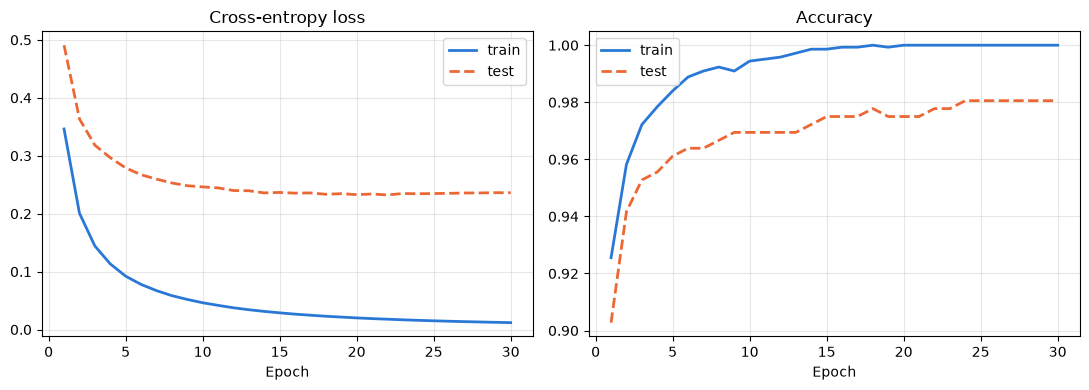

In [10]:
def plot_history(history):
    """Loss and accuracy per epoch, train vs. test."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, key, title in [(axes[0], "loss", "Cross-entropy loss"), (axes[1], "acc", "Accuracy")]:
        ax.plot(epochs, history[f"train_{key}"], color="#2a78d6", lw=2, label="train")
        ax.plot(epochs, history[f"test_{key}"], color="#eb6834", lw=2, ls="--", label="test")
        ax.set(title=title, xlabel="Epoch")
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()


y_test_pred = predict(trained_params, X_test)
test_acc = accuracy(trained_params, X_test, y_test)
print(f"Final test accuracy: {100 * test_acc:.2f} % ({np.sum(y_test_pred != y_test)} of 360 wrong)")
plot_history(history)
assert test_acc >= 0.90

The first 16 test images with their predicted and true labels; wrong predictions are red with a ✗. The images are drawn from the raw pixels (0–16), since standardized pixels look distorted.

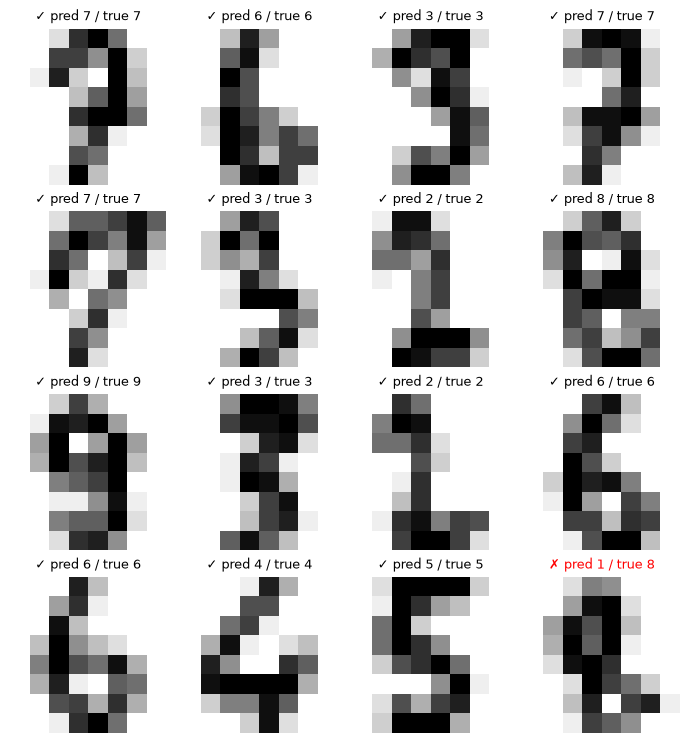

wrong among these 16: 1


In [11]:
def show_predictions(X_raw, y_true, y_pred):
    """4 x 4 grid of the first 16 images with predicted / true labels; wrong ones in red."""
    fig, axes = plt.subplots(4, 4, figsize=(7, 7.5))
    for i, ax in enumerate(axes.ravel()):
        ok = y_pred[i] == y_true[i]
        ax.imshow(X_raw[i].reshape(8, 8), cmap="gray_r")
        ax.set_title(f"{'✓' if ok else '✗'} pred {y_pred[i]} / true {y_true[i]}", fontsize=9, color="black" if ok else "red")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


show_predictions(X_test_raw, y_test, y_test_pred)
print("wrong among these 16:", np.sum(y_test_pred[:16] != y_test[:16]))

The confusion matrix counts test images by true class (rows) and predicted class (columns): the diagonal holds the correct ones, everything else is a mistake. `np.add.at` adds 1 at `(true, predicted)` for every image.

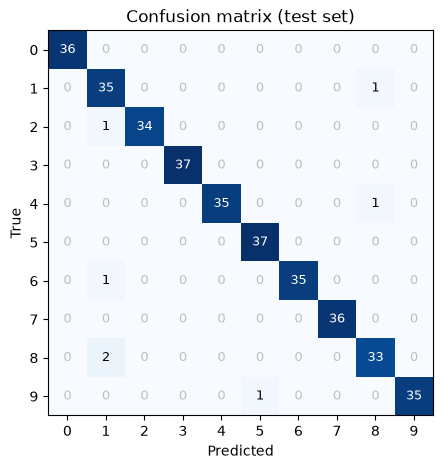

per-class accuracy (%): [100.   97.2  97.1 100.   97.2 100.   97.2 100.   94.3  97.2]


In [12]:
def plot_confusion_matrix(y_true, y_pred):
    """Count (true, predicted) pairs, show them as a heatmap, and return the 10 x 10 matrix."""
    C = np.zeros((10, 10), dtype=int)
    np.add.at(C, (y_true, y_pred), 1)
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.imshow(C, cmap="Blues")
    for i in range(10):
        for j in range(10):
            ax.text(j, i, C[i, j], ha="center", va="center", fontsize=9,
                    color="white" if C[i, j] > C.max() / 2 else ("0.75" if C[i, j] == 0 else "black"))
    ax.set(xticks=range(10), yticks=range(10), xlabel="Predicted", ylabel="True", title="Confusion matrix (test set)")
    plt.show()
    return C


C = plot_confusion_matrix(y_test, y_test_pred)
print("per-class accuracy (%):", np.round(100 * np.diag(C) / C.sum(axis=1), 1))
assert C.sum() == 360 and np.isclose(np.trace(C) / 360, test_acc)

**Interpretation.** Only 7 of 360 images are wrong; digits 0, 3, 5 and 7 are perfect. The weakest class is **8** (94.3 %), and both of its errors are predicted as **1**: the 1 ↔ 8 pair causes 3 of the 7 mistakes, because a thin 8 at 8 × 8 pixels is mostly a vertical stroke, like a 1.

## 6. Errors

Each of the four `spec.md` R8 cases is triggered on purpose and its `ValueError` message printed. Without these checks they would end in a cryptic NumPy error or fail silently (a label of −1 would quietly become class 9). The `NaN` case uses a learning rate of 5.0, far too large: its overflow warnings and progress lines are expected, so they are hidden here.

In [13]:
import contextlib, io

cases = {
    "dimension mismatch": lambda: forward(trained_params, X_test[:5, :63]),
    "empty mini-batch":   lambda: train_step(trained_params, X_train[:0], Y_train[:0], 0.1),
    "label out of range": lambda: one_hot(np.array([3, 7, 12])),
    "NaN loss":           lambda: train(params, (X_train, Y_train, X_test, Y_test), dict(CONFIG, learning_rate=5.0)),
}
raised = 0
with np.errstate(over="ignore", invalid="ignore"):
    for name, call in cases.items():
        try:
            with contextlib.redirect_stdout(io.StringIO()):   # hide the progress lines of the diverging run
                call()
            print(f"{name:<20} -> no error!")
        except ValueError as error:
            print(f"{name:<20} -> {error}")
            raised += 1
assert raised == 4

dimension mismatch   -> Layer 1 expects 64 inputs, but received 63.
empty mini-batch     -> Empty mini-batch: received 0 samples.
label out of range   -> Labels must be integers in 0-9; got 12 at index 2.
NaN loss             -> Loss is nan at epoch 8. Try a lower learning rate.
